# 05 — Baselines (final)

Computes paper-ready baseline numbers for EVE-RAG and combines all stream + baseline result tables into one summary table for the paper.

**Baselines included**
1. Random uniform predictor (the absolute floor).
2. Majority class predictor (per-dataset).
3. Always-match (always predict 0).
4. Always-mismatch (always predict 1).
5. CLIP cosine threshold (raw similarity ≥ median → match).
6. CLIP cosine rank baseline (percentile-rank score, AUROC reflects ranking quality).

**Outputs**
- `paper/tables/baseline_results.csv`
- `paper/tables/clip_baseline_results.csv`
- `paper/tables/all_streams_and_baselines_summary.csv`
- `paper/figures/all_streams_summary_bar.png`


In [1]:
# === ENVIRONMENT ===
from pathlib import Path
import sys, os, json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_repo_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "data").exists() and (q / "src").exists():
            return q
    raise RuntimeError("Could not find repo root.")

ROOT = find_repo_root()
sys.path.insert(0, str(ROOT))

from src.utils.paths import (
    STREAM_A_CACHE, STREAM_B_CACHE, STREAM_C_CACHE,
    ALL_MANIFEST, FIGURES, TABLES,
)

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

print("ROOT             :", ROOT)
print("ALL_MANIFEST     :", ALL_MANIFEST)
print("TABLES           :", TABLES)
print("FIGURES          :", FIGURES)

RNG = np.random.default_rng(42)


ROOT             : E:\eve-rag
ALL_MANIFEST     : E:\eve-rag\data\processed\ooc_pairs\manifests\all.csv
TABLES           : E:\eve-rag\paper\tables
FIGURES          : E:\eve-rag\paper\figures


In [2]:
# === LOAD MANIFEST + DEFINE EVAL SPLITS ===
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
)

df = pd.read_csv(ALL_MANIFEST, low_memory=False)
df["pair_id"] = df["pair_id"].astype(str)
print(f"Manifest shape: {df.shape}")
display(df.groupby(["dataset", "split"]).size().reset_index(name="rows"))

eval_sets = {
    "newsclippings_test": df[(df["dataset"] == "newsclippings") & (df["split"] == "test")],
    "mmfakebench_val":    df[(df["dataset"] == "mmfakebench")   & (df["split"] == "val")],
    "mmfakebench_test":   df[(df["dataset"] == "mmfakebench")   & (df["split"] == "test")],
    "verite_test":        df[(df["dataset"] == "verite")        & (df["split"] == "test")],
}
for k, v in eval_sets.items():
    print(f"  {k:22s}: {len(v):>6d} rows  |  pos rate = {v['label'].mean():.3f}")


Manifest shape: (97361, 24)


,dataset,split,rows
0,mmfakebench,test,10000
1,mmfakebench,val,1000
2,newsclippings,test,7264
3,newsclippings,train,71072
4,newsclippings,val,7024
5,verite,test,1001


  newsclippings_test    :   7264 rows  |  pos rate = 0.500
  mmfakebench_val       :   1000 rows  |  pos rate = 0.700
  mmfakebench_test      :  10000 rows  |  pos rate = 0.700
  verite_test           :   1001 rows  |  pos rate = 0.662


In [3]:
# === METRIC HELPER ===
def compute_metrics(y_true, y_pred=None, y_score=None):
    """Returns dict of acc/precision/recall/f1/auroc as percentages."""
    y_true = np.asarray(y_true).astype(int)
    if y_score is not None and y_pred is None:
        y_pred = (np.asarray(y_score) >= 0.5).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    out = {
        "acc":       round(accuracy_score(y_true, y_pred) * 100, 2),
        "precision": round(precision_score(y_true, y_pred, zero_division=0) * 100, 2),
        "recall":    round(recall_score(y_true, y_pred, zero_division=0) * 100, 2),
        "f1":        round(f1_score(y_true, y_pred, zero_division=0) * 100, 2),
        "auroc":     np.nan,
    }
    if y_score is not None and len(np.unique(y_true)) > 1:
        out["auroc"] = round(roc_auc_score(y_true, y_score) * 100, 2)
    return out

def metric_row(method, dataset_name, y_true, y_pred=None, y_score=None):
    return {"method": method, "dataset": dataset_name,
            **compute_metrics(y_true, y_pred=y_pred, y_score=y_score)}


In [4]:
# === CONSTANT / RANDOM BASELINES ===
rows = []
for name, sub in eval_sets.items():
    if len(sub) == 0:
        print(f"  skipping {name}: empty"); continue
    y = sub["label"].astype(int).values

    # Majority (whichever class has higher count in this eval split)
    majority_cls = int(np.mean(y) >= 0.5)
    rows.append(metric_row("majority", name, y,
                           y_pred=np.full_like(y, majority_cls)))

    # Always match (0) / always mismatch (1)
    rows.append(metric_row("always_match_0",    name, y, y_pred=np.zeros_like(y)))
    rows.append(metric_row("always_mismatch_1", name, y, y_pred=np.ones_like(y)))

    # Random uniform (5-seed average for stability)
    accs, f1s = [], []
    for seed in range(5):
        rng = np.random.default_rng(seed)
        rand_pred = rng.integers(0, 2, size=len(y))
        accs.append(accuracy_score(y, rand_pred))
        f1s.append(f1_score(y, rand_pred, zero_division=0))
    rows.append({
        "method": "random_uniform", "dataset": name,
        "acc":       round(float(np.mean(accs)) * 100, 2),
        "precision": np.nan, "recall": np.nan,
        "f1":        round(float(np.mean(f1s)) * 100, 2),
        "auroc":     50.00,
    })

baseline = pd.DataFrame(rows)
baseline.to_csv(TABLES / "baseline_results.csv", index=False)
print(f"Wrote {TABLES / 'baseline_results.csv'}")
display(baseline)


Wrote E:\eve-rag\paper\tables\baseline_results.csv


,method,dataset,acc,precision,recall,f1,auroc
0,majority,newsclippings_test,50.00,50.00,100.0,66.67,NaN
1,always_match_0,newsclippings_test,50.00,0.00,0.0,0.00,NaN
2,always_mismatch_1,newsclippings_test,50.00,50.00,100.0,66.67,NaN
3,random_uniform,newsclippings_test,49.98,NaN,NaN,49.81,50.0
4,majority,mmfakebench_val,70.00,70.00,100.0,82.35,NaN
5,always_match_0,mmfakebench_val,30.00,0.00,0.0,0.00,NaN
6,always_mismatch_1,mmfakebench_val,70.00,70.00,100.0,82.35,NaN
7,random_uniform,mmfakebench_val,49.52,NaN,NaN,58.22,50.0
8,majority,mmfakebench_test,70.00,70.00,100.0,82.35,NaN
9,always_match_0,mmfakebench_test,30.00,0.00,0.0,0.00,NaN


In [5]:
# === CLIP COSINE BASELINES (raw threshold + percentile rank) ===
clip_path = STREAM_B_CACHE / "features" / "clip_features_all.csv"
clip_rows = []

if clip_path.exists():
    clip = pd.read_csv(clip_path, low_memory=False)
    clip["pair_id"] = clip["pair_id"].astype(str)
    print(f"Loaded CLIP features: {clip.shape}")

    if "clip_cosine" not in clip.columns:
        print("  ⚠  'clip_cosine' column not found — skipping CLIP baselines.")
    else:
        # Higher cosine ⇒ image-text are more similar ⇒ more likely to MATCH (label 0).
        # We score "mismatch likelihood" as 1 − cosine (higher score ⇒ more likely OOC).
        for name, sub_ids in eval_sets.items():
            sub = clip[clip["pair_id"].isin(sub_ids["pair_id"])]
            if len(sub) == 0:
                print(f"  {name}: no CLIP feature overlap, skipping"); continue
            y = sub["label"].astype(int).values
            cos = sub["clip_cosine"].astype(float).values

            # Raw threshold: "mismatch" if cosine below median of split
            thr = float(np.median(cos))
            pred_raw = (cos < thr).astype(int)
            score_raw = 1.0 - cos  # higher ⇒ more likely OOC
            clip_rows.append(metric_row(
                "clip_cosine_threshold", name, y,
                y_pred=pred_raw, y_score=score_raw,
            ))

            # Percentile rank score (preserves AUROC, threshold-free interpretation)
            score_rank = pd.Series(-cos).rank(pct=True).values
            clip_rows.append(metric_row(
                "clip_cosine_rank", name, y, y_score=score_rank,
            ))

    clip_base = pd.DataFrame(clip_rows)
    if len(clip_base):
        clip_base.to_csv(TABLES / "clip_baseline_results.csv", index=False)
        print(f"Wrote {TABLES / 'clip_baseline_results.csv'}")
        display(clip_base)
else:
    print(f"  ⚠  No Stream B CLIP features at {clip_path} — skipping CLIP baselines.")


Loaded CLIP features: (97361, 13)
Wrote E:\eve-rag\paper\tables\clip_baseline_results.csv


,method,dataset,acc,precision,recall,f1,auroc
0,clip_cosine_threshold,newsclippings_test,65.75,65.75,65.75,65.75,71.97
1,clip_cosine_rank,newsclippings_test,65.74,65.73,65.75,65.74,71.97
2,clip_cosine_threshold,mmfakebench_val,53.40,73.40,52.43,61.17,55.06
3,clip_cosine_rank,mmfakebench_val,53.50,73.45,52.57,61.28,55.06
4,clip_cosine_threshold,mmfakebench_test,58.12,78.12,55.80,65.10,64.13
5,clip_cosine_rank,mmfakebench_test,58.13,78.12,55.81,65.11,64.13
6,clip_cosine_threshold,verite_test,48.35,64.60,48.72,55.55,48.54
7,clip_cosine_rank,verite_test,48.25,64.47,48.72,55.50,48.54


In [6]:
# === COMBINE STREAM + BASELINE TABLES ===
TABLE_SOURCES = [
    ("stream_a_results.csv",     "stream_a"),
    ("stream_b_results.csv",     "stream_b"),
    ("stream_c_results.csv",     "stream_c"),
    ("baseline_results.csv",     "baseline"),
    ("clip_baseline_results.csv","clip_baseline"),
]

frames = []
for fname, tag in TABLE_SOURCES:
    p = TABLES / fname
    if p.exists():
        t = pd.read_csv(p)
        t["source_table"] = tag
        frames.append(t)
        print(f"  ✓ loaded {fname:36s} ({len(t)} rows)")
    else:
        print(f"  ✗ missing {fname}")

combined = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
out_csv = TABLES / "all_streams_and_baselines_summary.csv"
combined.to_csv(out_csv, index=False)
print(f"\nWrote {out_csv}  ({len(combined)} rows)")

# Pretty pivot for the paper: rows = method, columns = dataset, values = accuracy
if len(combined):
    pivot_acc = combined.pivot_table(
        index=["source_table", "method"], columns="dataset", values="acc", aggfunc="first"
    )
    print("\nAccuracy (%) per method × dataset:")
    display(pivot_acc.round(2))


  ✓ loaded stream_a_results.csv                 (6 rows)
  ✓ loaded stream_b_results.csv                 (4 rows)
  ✓ loaded stream_c_results.csv                 (8 rows)
  ✓ loaded baseline_results.csv                 (16 rows)
  ✓ loaded clip_baseline_results.csv            (8 rows)

Wrote E:\eve-rag\paper\tables\all_streams_and_baselines_summary.csv  (42 rows)

Accuracy (%) per method × dataset:


dataset                                mmfakebench_test  mmfakebench_val  \
source_table  method                                                       
baseline      always_match_0                      30.00            30.00   
              always_mismatch_1                   70.00            70.00   
              majority                            70.00            70.00   
              random_uniform                      49.55            49.52   
clip_baseline clip_cosine_rank                    58.13            53.50   
              clip_cosine_threshold               58.12            53.40   
stream_a      caption_clip_sim_median             58.10              NaN   
              majority_train                      70.00              NaN   
              stream_a_lr                         62.56              NaN   

dataset                                newsclippings_test  verite_test  \
source_table  method                                                     
baseline      always_match_0                        50.00        33.77   
              always_mismatch_1                     50.00        66.23   
              majority                              50.00        66.23   
              random_uniform                        49.98        50.91   
clip_baseline clip_cosine_rank                      65.74        48.25   
              clip_cosine_threshold                 65.75        48.35   
stream_a      caption_clip_sim_median                 NaN          NaN   
              majority_train                          NaN          NaN   
              stream_a_lr                             NaN          NaN   

dataset                                verite_test_local  
source_table  method                                      
baseline      always_match_0                         NaN  
              always_mismatch_1                      NaN  
              majority                               NaN  
              random_uniform                         NaN  
clip_baseline clip_cosine_rank                       NaN  
              clip_cosine_threshold                  NaN  
stream_a      caption_clip_sim_median              48.47  
              majority_train                       66.51  
              stream_a_lr                          53.30

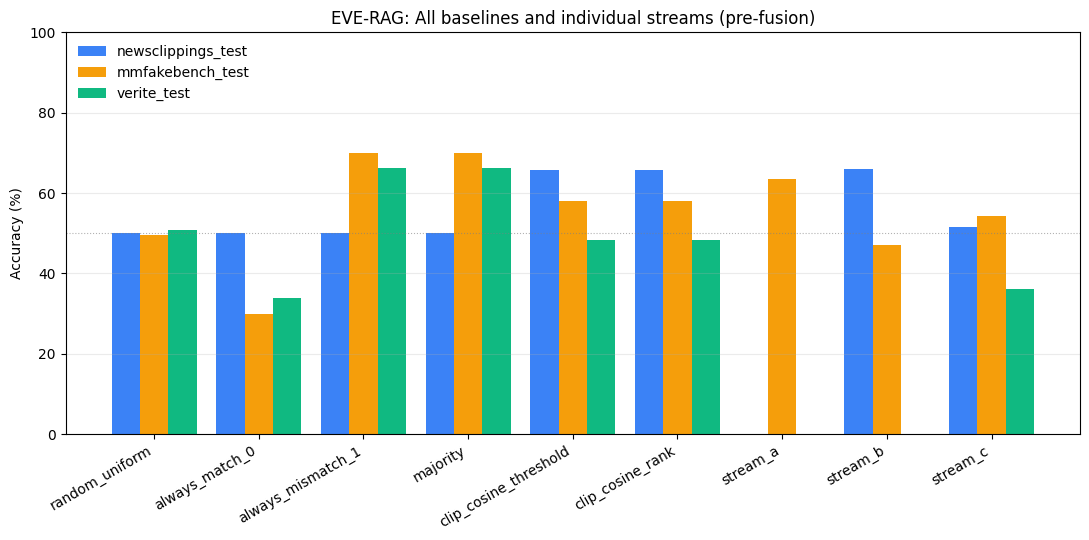


Saved E:\eve-rag\paper\figures\all_streams_summary_bar.png


In [7]:
# === PAPER-READY SUMMARY FIGURE ===
if len(combined) == 0:
    print("Nothing to plot — combined table is empty.")
else:
    # Subset: one row per method, accuracy per dataset
    METHOD_ORDER = [
        "random_uniform", "always_match_0", "always_mismatch_1", "majority",
        "clip_cosine_threshold", "clip_cosine_rank",
        "stream_a", "stream_b", "stream_c",
    ]
    DATASET_ORDER = ["newsclippings_test", "mmfakebench_test", "verite_test"]

    # Pull one accuracy number per (method, dataset). For Stream A/B/C tables
    # the method column may be the dataset name, so we re-tag.
    plot_rows = []
    for _, r in combined.iterrows():
        m = r["method"]
        st = r["source_table"]
        d = r["dataset"]
        if st in ("stream_a", "stream_b", "stream_c"):
            m = st  # Stream-level rows: collapse to one bar per stream
        if d not in DATASET_ORDER:
            continue
        plot_rows.append({"method": m, "dataset": d, "acc": r["acc"]})

    plot_df = (pd.DataFrame(plot_rows)
               .groupby(["method", "dataset"], as_index=False)["acc"].mean())
    methods = [m for m in METHOD_ORDER if m in plot_df["method"].unique()]

    fig, ax = plt.subplots(figsize=(11, 5.5))
    width = 0.27
    x = np.arange(len(methods))
    colors = {
        "newsclippings_test": "#3b82f6",
        "mmfakebench_test":   "#f59e0b",
        "verite_test":        "#10b981",
    }
    for i, d in enumerate(DATASET_ORDER):
        vals = [plot_df[(plot_df["method"] == m) & (plot_df["dataset"] == d)]["acc"].mean()
                if ((plot_df["method"] == m) & (plot_df["dataset"] == d)).any() else np.nan
                for m in methods]
        ax.bar(x + (i - 1) * width, vals, width, label=d, color=colors[d])

    ax.set_xticks(x)
    ax.set_xticklabels(methods, rotation=30, ha="right")
    ax.set_ylabel("Accuracy (%)")
    ax.set_title("EVE-RAG: All baselines and individual streams (pre-fusion)")
    ax.axhline(50, color="gray", linestyle=":", linewidth=0.8, alpha=0.6)
    ax.set_ylim(0, 100)
    ax.legend(loc="upper left", frameon=False)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    out_fig = FIGURES / "all_streams_summary_bar.png"
    plt.savefig(out_fig, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"\nSaved {out_fig}")


In [8]:
# === DONE ===
print("Baselines complete.")
print("Tables  :", TABLES)
print("Figures :", FIGURES)
print("Combined summary:", TABLES / "all_streams_and_baselines_summary.csv")


Baselines complete.
Tables  : E:\eve-rag\paper\tables
Figures : E:\eve-rag\paper\figures
Combined summary: E:\eve-rag\paper\tables\all_streams_and_baselines_summary.csv
